# Own methodology vs. PECD (multi-year, ERA5-driven)

Does this hub's own from-scratch capacity-factor chain (GWA wind-speed
bias correction, hub-height extrapolation, per-plant turbine curves,
PECD-documented solar chain -- `edh.forecast_capacity_factors`, the
*same* code `energy-data-hub`'s WeatherNext asset uses, just fed
`era5_grid`'s real reanalysis instead of a forecast) **track PECD's own
official capacity-factor product**, over several years? Deliberately fed
real historical weather, never a forecast -- isolates the weather-to-power
**conversion methodology** from any forecast-model-skill question, unlike
`16_weathernext_forecast_vs_pecd.py`.

Both sides use **today's real, pinned MaStR fleet** held fixed across the
whole historical window (the hub's established "current fleet" convention
-- see `edh.forecast_capacity_factors`'s own module docstring), not a
historically-accurate per-year fleet. That's fine for *this* comparison --
own-methodology and PECD both use the exact same (today's) fleet weights,
so the fleet choice cancels out and doesn't bias the comparison either way.

**Not yet included here: PECD vs. real SMARD generation.** That
comparison needs the fleet's *actual, historically-accurate* size at
each past date (SMARD's real generation reflects whatever fleet existed
in e.g. 2019, not today's much larger one) -- mixing in today's fixed
fleet would conflate "does PECD's weather-to-power conversion match
reality" with "how much has the fleet grown since", which isn't a clean
question. The hub already has the right building block for this,
unused so far: `edh.pecd`'s "historic" weighting variant
(`capacity_monthly_panel` -> `compute_potential_monthly`, each hour
weighted by *that calendar month's* actual installed capacity -- see
that module's docstring) instead of the "current fleet" variant used
here. Left for a follow-up once this first comparison looks sound.

**Window:** every month with both ERA5 and PECD on disk -- currently
2018-10 through 2025-12 (PECD's own official product stops at 2025; see
`edh.pecd.YEARS`). The own-methodology chain is computed once per month
by `edh.forecast_capacity_factors.compute_and_save_month` (a disk-cached
step, not re-run by this notebook -- see that function's own docstring)
and read back here.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

from edh.forecast_capacity_factors import active_solar_configs, active_wind_plants
from edh.pecd import expand_wind_zone_weights
from edh.paths import era5_capacity_factors_month_file, pecd_capacity_factors_file, pecd_mask_file

from insights.paths import HUB_DATA

COLORS = {"own": "#2a78d6", "pecd": "#eb6834"}
LABELS = {"own": "Own methodology (ERA5-fed)", "pecd": "PECD (official product)"}
TECH_LABELS = {"pv": "Solar PV", "wind_onshore": "Wind onshore", "wind_offshore": "Wind offshore", "full_re": "Full RE (blend)"}
TECHS = ["pv", "wind_onshore", "wind_offshore", "full_re"]
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SURFACE = "#fcfcfb"

## Today's real fleet, as the fixed weighting basis for every series here

Same "current pinned snapshot" convention as `16_weathernext_forecast_vs_
pecd.py` -- `expand_wind_zone_weights` (wind, PEON/PEOF zones) and a
straight per-(region, technology) capacity grouping (solar), both
already-validated hub functions, reused as-is.

In [2]:
as_of = pd.Timestamp.now().normalize()
onshore, offshore = active_wind_plants(as_of)
configs = active_solar_configs(as_of)
cap_onshore, cap_offshore, cap_pv = onshore["capacity_mw"].sum(), offshore["capacity_mw"].sum(), configs["capacity_mw"].sum()
cap_total = cap_onshore + cap_offshore + cap_pv
print(f"Today's fleet (MW): onshore={cap_onshore:,.0f}  offshore={cap_offshore:,.0f}  pv={cap_pv:,.0f}  total={cap_total:,.0f}")

onshore_weights = expand_wind_zone_weights(onshore, pecd_mask_file("peon")).groupby("zone_id")["capacity_mw"].sum()
offshore_weights = expand_wind_zone_weights(offshore, pecd_mask_file("peof")).groupby("zone_id")["capacity_mw"].sum()
solar_weights = configs.groupby(["nuts2_region", "pecd_technology"])["capacity_mw"].sum()


def blend_pecd_to_national(wind_onshore_de: pd.DataFrame, wind_offshore_de: pd.DataFrame, solar_de_by_tech: dict) -> pd.DataFrame:
    """PECD's own zone/region-columned product, blended to one Germany
    number per technology + a capacity-weighted `full_re` blend, using
    today's real fleet weights -- identical approach to
    `16_weathernext_forecast_vs_pecd.py::blend_to_national`."""
    common_on = [z for z in onshore_weights.index if z in wind_onshore_de.columns]
    w_on = onshore_weights[common_on] / onshore_weights[common_on].sum()
    cf_onshore = (wind_onshore_de[common_on] * w_on).sum(axis=1)

    common_off = [z for z in offshore_weights.index if z in wind_offshore_de.columns]
    w_off = offshore_weights[common_off] / offshore_weights[common_off].sum()
    cf_offshore = (wind_offshore_de[common_off] * w_off).sum(axis=1)

    cf_pv = pd.Series(0.0, index=solar_de_by_tech["60"].index)
    weight_total = 0.0
    for (region, tech), weight in solar_weights.items():
        if region in solar_de_by_tech[tech].columns:
            cf_pv = cf_pv.add(solar_de_by_tech[tech][region] * weight, fill_value=0)
            weight_total += weight
    cf_pv = cf_pv / weight_total
    cf_pv.index = cf_pv.index - pd.Timedelta(hours=1)  # PECD's documented solar-only 1h timestamp shift

    full_re = (cf_pv * cap_pv + cf_onshore * cap_onshore + cf_offshore * cap_offshore) / cap_total
    return pd.DataFrame({"pv": cf_pv, "wind_onshore": cf_onshore, "wind_offshore": cf_offshore, "full_re": full_re}).dropna(how="all")

Today's fleet (MW): onshore=69,203  offshore=10,595  pv=111,491  total=191,289


## PECD, 2015-2025, blended to national

In [3]:
wind_onshore_hist = pd.read_parquet(pecd_capacity_factors_file("wind_onshore"))
wind_offshore_hist = pd.read_parquet(pecd_capacity_factors_file("wind_offshore"))
solar_hist_multi = pd.read_parquet(pecd_capacity_factors_file("solar"))
pecd = blend_pecd_to_national(wind_onshore_hist, wind_offshore_hist, {t: solar_hist_multi[t] for t in ["60", "61", "62", "63"]})
print(f"PECD: {pecd.index.min()} .. {pecd.index.max()} ({len(pecd)} rows)")

PECD: 2014-12-31 22:00:00 .. 2026-08-31 23:00:00 (102266 rows)


## Own methodology, fed ERA5 -- every month already computed and cached

Reads `era5_capacity_factors_month_file`'s output directly (written by
`edh.forecast_capacity_factors.compute_and_save_month`, run once ahead of
time as a backfill over every `era5_grid` month on disk -- not
recomputed here, same reasoning as `forecast_capacity_factors_de`'s own
per-day cache: the full chain costs real per-month compute time, not
something a notebook re-execution should redo).

In [4]:
cf_dir = HUB_DATA / "era5_capacity_factors"
month_files = sorted(cf_dir.glob("*.parquet"))
own_parts = [pd.read_parquet(f).assign(year_month=f.stem) for f in month_files]
own = pd.concat(own_parts, ignore_index=True).set_index("valid_time").drop(columns="year_month").sort_index()
own["full_re"] = (own["pv"] * cap_pv + own["wind_onshore"] * cap_onshore + own["wind_offshore"] * cap_offshore) / cap_total
print(f"Own (ERA5-fed): {own.index.min()} .. {own.index.max()} ({len(own)} rows, {len(month_files)} months)")

Own (ERA5-fed): 2018-10-01 00:00:00 .. 2026-07-31 23:00:00 (68664 rows, 94 months)


## Per-technology comparison, monthly mean, full overlapping window

Overlap used for charts + metrics: 2018-10-01 00:00:00 .. 2026-07-31 23:00:00


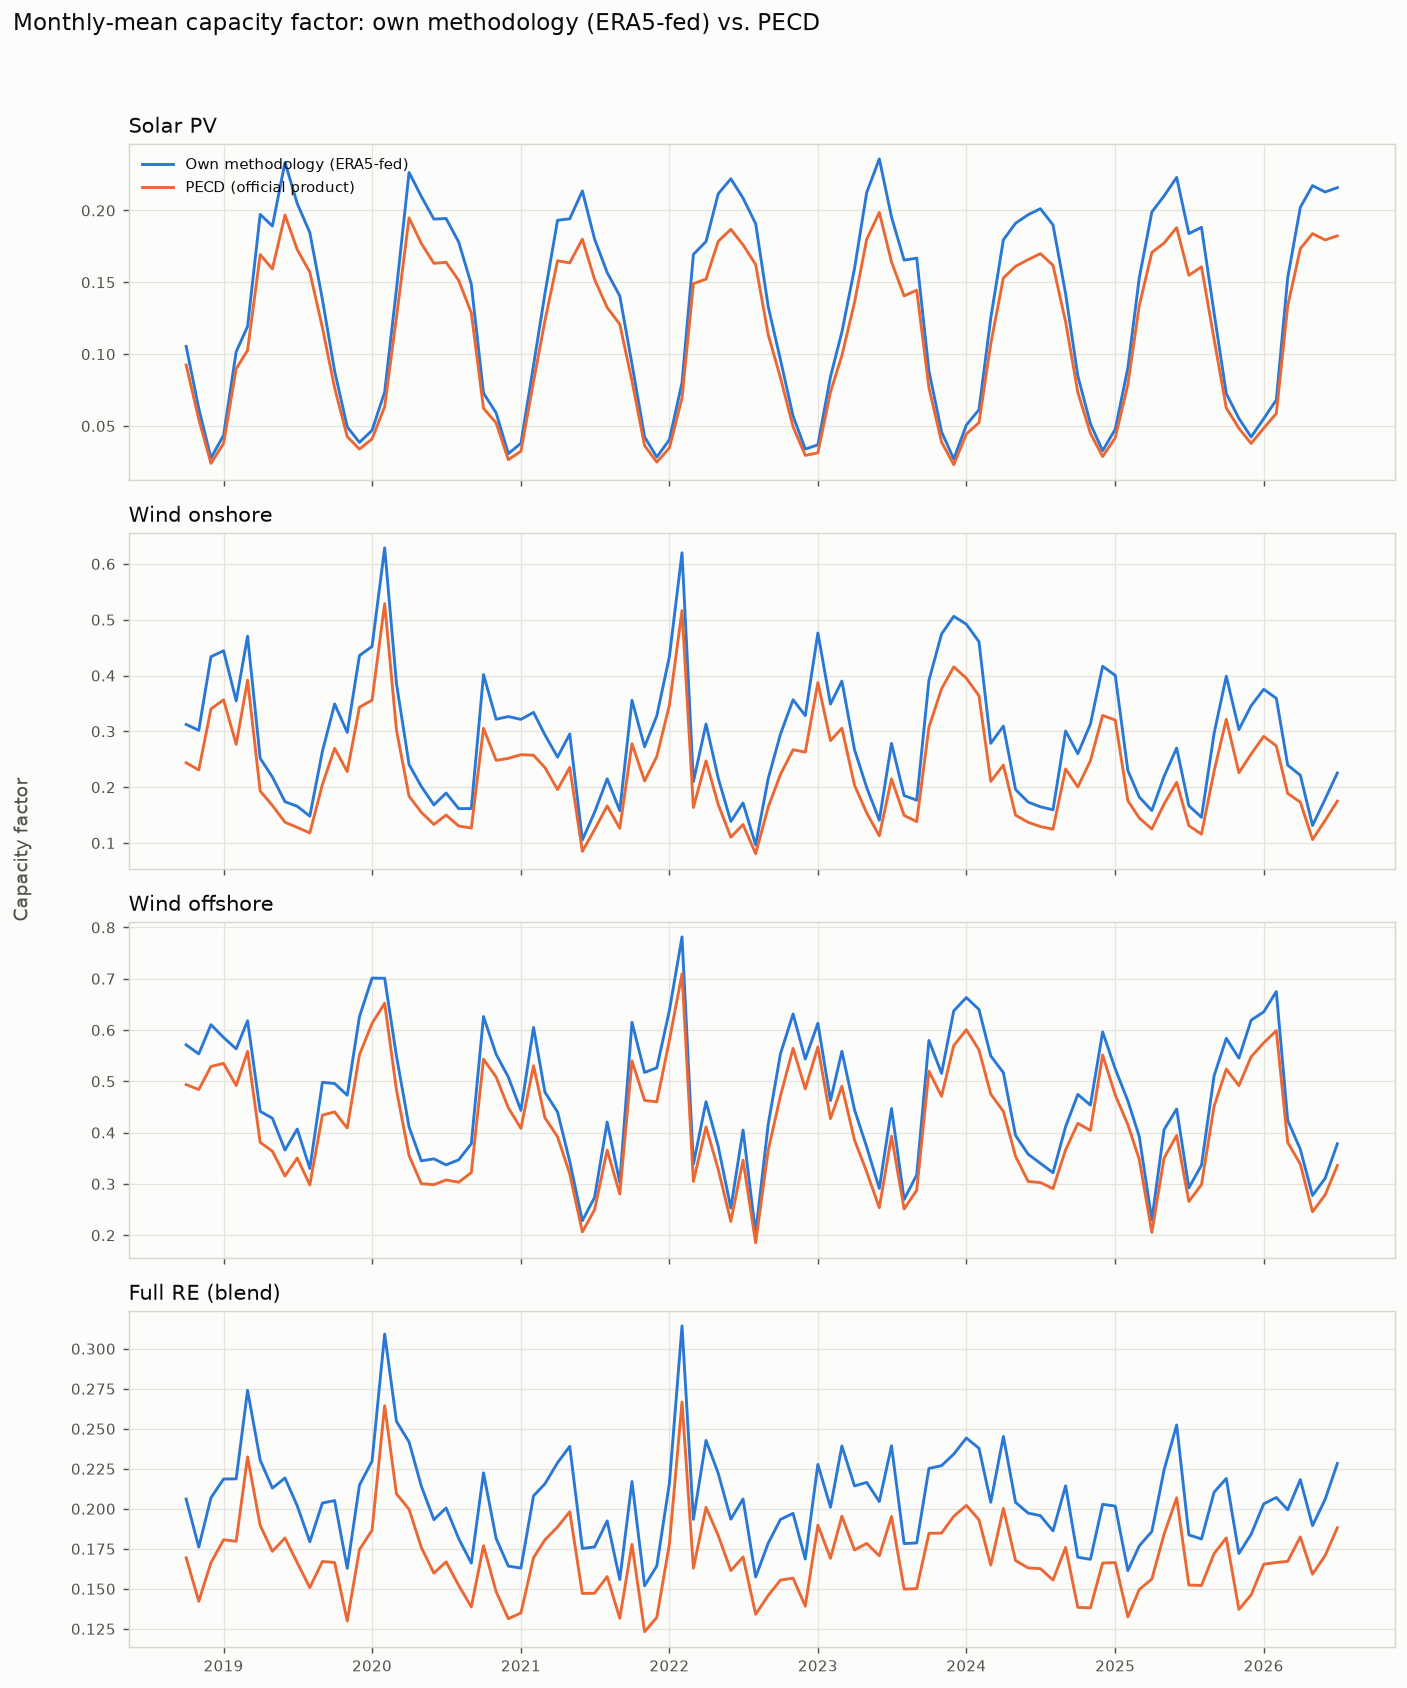

In [5]:
import matplotlib.pyplot as plt

overlap_start = max(own.index.min(), pecd.index.min())
overlap_end = min(own.index.max(), pecd.index.max())
print(f"Overlap used for charts + metrics: {overlap_start} .. {overlap_end}")

own_m = own.loc[overlap_start:overlap_end].resample("MS").mean()
pecd_m = pecd.loc[overlap_start:overlap_end].resample("MS").mean()

fig, axes = plt.subplots(len(TECHS), 1, figsize=(11, 13), dpi=130, sharex=True)
fig.patch.set_facecolor(SURFACE)
for ax, tech in zip(axes, TECHS):
    ax.set_facecolor(SURFACE)
    ax.plot(own_m.index, own_m[tech], color=COLORS["own"], linewidth=1.6, label=LABELS["own"])
    ax.plot(pecd_m.index, pecd_m[tech], color=COLORS["pecd"], linewidth=1.6, label=LABELS["pecd"])
    ax.set_title(TECH_LABELS[tech], color=TEXT_PRIMARY, fontsize=11.5, loc="left")
    ax.grid(True, color="#e5e3dc", linewidth=0.7)
    for spine in ax.spines.values():
        spine.set_color("#d8d6cd")
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=8.5)
axes[0].legend(loc="upper left", frameon=False, fontsize=8.5, labelcolor=TEXT_PRIMARY)
fig.suptitle("Monthly-mean capacity factor: own methodology (ERA5-fed) vs. PECD", color=TEXT_PRIMARY, fontsize=12.5, x=0.02, ha="left", y=0.995)
fig.supylabel("Capacity factor", color=TEXT_SECONDARY, fontsize=10.5)
fig.tight_layout(rect=[0.02, 0.0, 1, 0.97])
plt.show()

## Metrics: own methodology vs. PECD, at every aggregation level, CF and MW

The same correlation/MAE/NMAE/bias as before, but now at **six**
aggregation levels (hourly through monthly -- each level resamples both
series to that frequency's mean *before* comparing, so e.g. "daily"
compares daily-mean capacity factors, not hourly values within a day)
and in **two units**: the normalized capacity factor used everywhere
else on this page, and the real power (MW) it implies against **today's
fixed fleet capacity** for that technology -- same capacity used
throughout this page, so the MW metrics are a rescaling of the CF ones,
not an independent measurement. CF alone makes cross-technology
comparison easy (solar/wind onshore/offshore are all 0-1); MW puts the
error back in context of each technology's actual real-world scale
(wind offshore's smaller fleet means its CF errors matter less in MW
terms than onshore's, even where NMAE looks similar).

In [6]:
AGG_FREQS = [("1h", "Hourly"), ("2h", "2-hourly"), ("1D", "Daily"), ("1W", "Weekly"), ("1MS", "Monthly")]
TECH_CAPACITY_MW = {"pv": cap_pv, "wind_onshore": cap_onshore, "wind_offshore": cap_offshore, "full_re": cap_total}


def compare(a: pd.Series, b: pd.Series) -> dict:
    joined = pd.DataFrame({"a": a, "b": b}).dropna()
    err = joined["a"] - joined["b"]
    return {
        "n": len(joined),
        "corr": joined["a"].corr(joined["b"]),
        "mae": err.abs().mean(),
        "nmae": err.abs().mean() / joined["b"].mean(),
        "bias": err.mean(),
    }


own_h = own.loc[overlap_start:overlap_end]
pecd_h = pecd.loc[overlap_start:overlap_end]

rows = []
for tech in TECHS:
    cap_mw = TECH_CAPACITY_MW[tech]
    for freq, freq_label in AGG_FREQS:
        own_r = own_h[tech].resample(freq).mean()
        pecd_r = pecd_h[tech].resample(freq).mean()
        rows.append({"technology": TECH_LABELS[tech], "aggregation": freq_label, "unit": "capacity factor", **compare(own_r, pecd_r)})
        rows.append({"technology": TECH_LABELS[tech], "aggregation": freq_label, "unit": "MW", **compare(own_r * cap_mw, pecd_r * cap_mw)})

metrics = pd.DataFrame(rows).set_index(["technology", "aggregation", "unit"]).round(4)
metrics

n    corr         mae  \
technology      aggregation unit                                         
Solar PV        Hourly      capacity factor  68664  0.8228      0.0694   
                            MW               68664  0.8228   7734.7654   
                2-hourly    capacity factor  34332  0.8284      0.0683   
                            MW               34332  0.8284   7617.1631   
                Daily       capacity factor   2861  0.9993      0.0190   
                            MW                2861  0.9993   2120.6465   
                Weekly      capacity factor    409  0.9996      0.0190   
                            MW                 409  0.9996   2121.8005   
                Monthly     capacity factor     94  0.9997      0.0190   
                            MW                  94  0.9997   2117.3774   
Wind onshore    Hourly      capacity factor  68664  0.9905      0.0620   
                            MW               68664  0.9905   4287.6648   
                2-hourly    capacity factor  34332  0.9909      0.0618   
                            MW               34332  0.9909   4277.7448   
                Daily       capacity factor   2861  0.9938      0.0612   
                            MW                2861  0.9938   4235.8475   
                Weekly      capacity factor    409  0.9964      0.0612   
                            MW                 409  0.9964   4232.4760   
                Monthly     capacity factor     94  0.9975      0.0613   
                            MW                  94  0.9975   4239.2932   
Wind offshore   Hourly      capacity factor  68664  0.9825      0.0672   
                            MW               68664  0.9825    711.8366   
                2-hourly    capacity factor  34332  0.9830      0.0668   
                            MW               34332  0.9830    707.2853   
                Daily       capacity factor   2861  0.9892      0.0600   
                            MW                2861  0.9892    635.4945   
                Weekly      capacity factor    409  0.9937      0.0527   
                            MW                 409  0.9937    558.7927   
                Monthly     capacity factor     94  0.9964      0.0520   
                            MW                  94  0.9964    550.6627   
Full RE (blend) Hourly      capacity factor  68664  0.8667      0.0569   
                            MW               68664  0.8667  10893.5076   
                2-hourly    capacity factor  34332  0.8721      0.0561   
                            MW               34332  0.8721  10722.4921   
                Daily       capacity factor   2861  0.9931      0.0361   
                            MW                2861  0.9931   6904.5216   
                Weekly      capacity factor    409  0.9949      0.0361   
                            MW                 409  0.9949   6904.3148   
                Monthly     capacity factor     94  0.9943      0.0361   
                            MW                  94  0.9943   6907.3334   

                                               nmae       bias  
technology      aggregation unit                                
Solar PV        Hourly      capacity factor  0.6222     0.0190  
                            MW               0.6222  2120.6465  
                2-hourly    capacity factor  0.6127     0.0190  
                            MW               0.6127  2120.6465  
                Daily       capacity factor  0.1706     0.0190  
                            MW               0.1706  2120.6465  
                Weekly      capacity factor  0.1706     0.0190  
                            MW               0.1706  2121.8005  
                Monthly     capacity factor  0.1705     0.0190  
                            MW               0.1705  2117.3774  
Wind onshore    Hourly      capacity factor  0.2753     0.0612  
                            MW               0.2753  4233.6534  
                2-hourly    ca

## Seasonality of the methodology gap: year x month MAE heatmap

Mean absolute error (capacity-factor units, own methodology vs. PECD),
one cell per (year, calendar month) -- computed from the native hourly
errors within that month, not the monthly-mean series (a monthly mean
of errors can cancel out through the month; this is the mean of
|hourly error|, so it reflects genuine within-month mismatch, not just
a shifted monthly average). Sequential, single-hue (blue), light=low
error -> dark=high error, one hue ramp per the project's own palette
(`references/palette.md`'s sequential blue steps), each panel scaled to
its own technology's error range since solar/wind magnitudes differ
structurally.

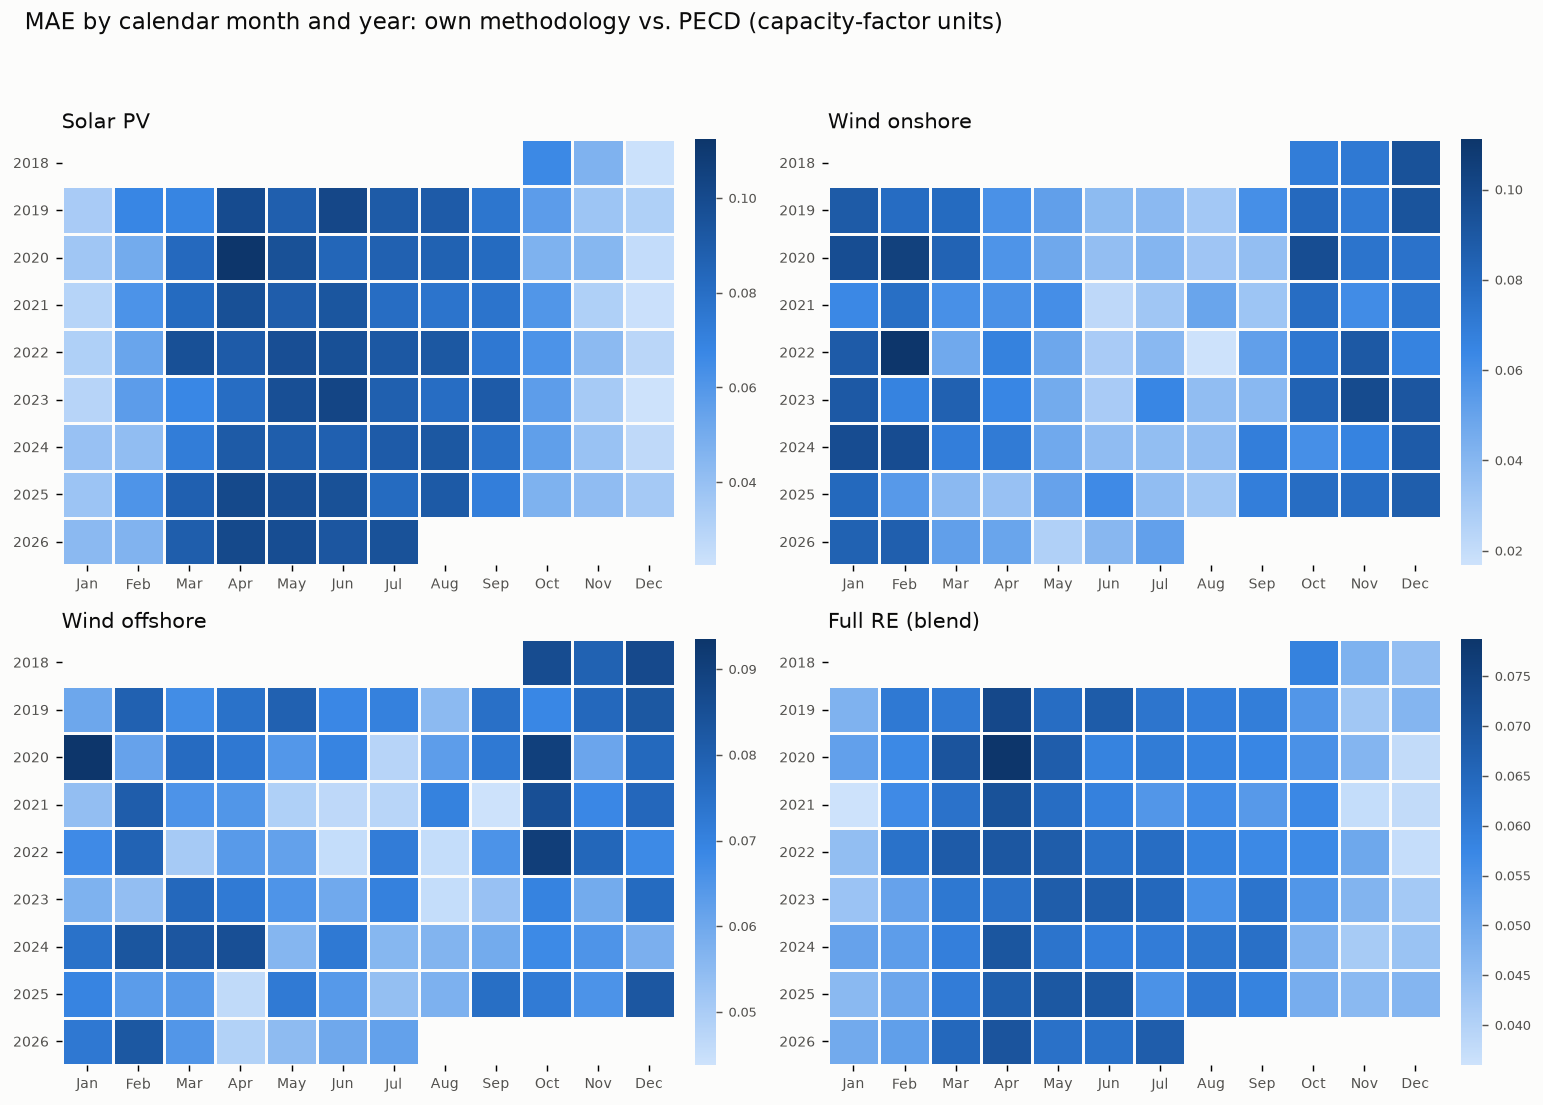

In [7]:
from matplotlib.colors import LinearSegmentedColormap

MAE_CMAP = LinearSegmentedColormap.from_list(
    "mae_blue",
    ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
)
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

err_h = (own_h - pecd_h).abs()
err_h["year"] = err_h.index.year
err_h["month"] = err_h.index.month

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), dpi=130)
fig.patch.set_facecolor(SURFACE)
for ax, tech in zip(axes.flat, TECHS):
    ax.set_facecolor(SURFACE)
    pivot = err_h.groupby(["year", "month"])[tech].mean().unstack("month").reindex(columns=range(1, 13))
    im = ax.pcolormesh(pivot.values, cmap=MAE_CMAP, edgecolors=SURFACE, linewidth=1.5)
    ax.set_xticks(np.arange(12) + 0.5)
    ax.set_xticklabels(MONTH_LABELS, fontsize=7.5, color=TEXT_SECONDARY)
    ax.set_yticks(np.arange(len(pivot.index)) + 0.5)
    ax.set_yticklabels(pivot.index, fontsize=7.5, color=TEXT_SECONDARY)
    ax.invert_yaxis()
    ax.set_title(TECH_LABELS[tech], color=TEXT_PRIMARY, fontsize=11.5, loc="left")
    for spine in ax.spines.values():
        spine.set_visible(False)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cbar.ax.tick_params(labelsize=7, colors=TEXT_SECONDARY)
    cbar.outline.set_visible(False)
fig.suptitle("MAE by calendar month and year: own methodology vs. PECD (capacity-factor units)", color=TEXT_PRIMARY, fontsize=12.5, x=0.02, ha="left", y=0.995)
fig.tight_layout(rect=[0.0, 0.0, 1, 0.96])
plt.show()

## Own methodology vs. PECD, hourly, scatter

Every hour in the overlapping window, one point per (own, PECD) pair --
a single series (one hue, no legend needed), small markers + low alpha
since this is tens of thousands of hourly points per panel (a solid
dot-for-dot scatter would just be a blob at this n); the dashed diagonal
is the "PECD exactly matched" reference, not a fitted line.

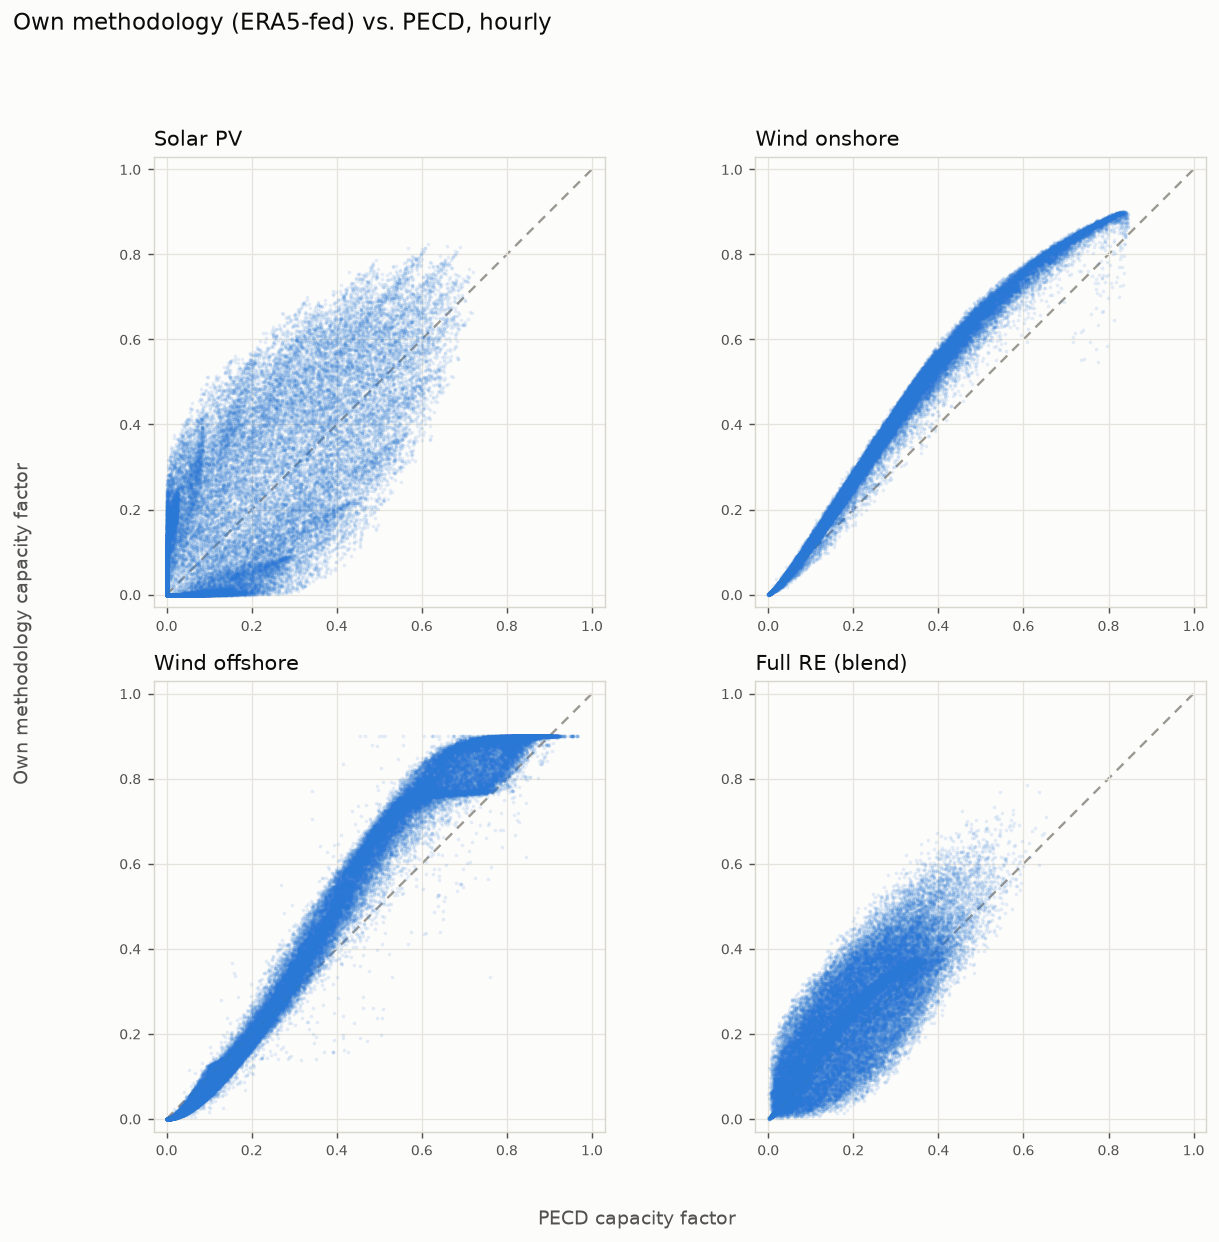

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9.5), dpi=130)
fig.patch.set_facecolor(SURFACE)
for ax, tech in zip(axes.flat, TECHS):
    ax.set_facecolor(SURFACE)
    ax.scatter(pecd_h[tech], own_h[tech], s=4, color=COLORS["own"], alpha=0.12, linewidths=0, zorder=2)
    ax.plot([0, 1], [0, 1], linestyle=(0, (4, 3)), linewidth=1.3, color="#9a9890", zorder=1)
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.set_aspect("equal")
    ax.set_title(TECH_LABELS[tech], color=TEXT_PRIMARY, fontsize=11.5, loc="left")
    ax.grid(True, color="#e5e3dc", linewidth=0.7, zorder=0)
    for spine in ax.spines.values():
        spine.set_color("#d8d6cd")
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=8)
fig.suptitle("Own methodology (ERA5-fed) vs. PECD, hourly", color=TEXT_PRIMARY, fontsize=12.5, x=0.02, ha="left", y=0.995)
fig.supxlabel("PECD capacity factor", color=TEXT_SECONDARY, fontsize=10.5)
fig.supylabel("Own methodology capacity factor", color=TEXT_SECONDARY, fontsize=10.5)
fig.tight_layout(rect=[0.02, 0.02, 1, 0.95])
plt.show()